# UNIVERSIDAD EXTERNADO DE COLOMBIA · CIENCIA DE DATOS · 2026

## Análisis de interpretabilidad mediante valores SHAP

**Predicción de la Estancia Hospitalaria con Aprendizaje Automático — SPARCS CY2021**

Autores: Daniel Vallejo Vecil · Juliana M.

---

Este cuaderno cuantifica la contribución de cada predictor a las estimaciones del modelo seleccionado
—XGBoost con pérdida de Tweedie, parámetro de varianza 1,5, en configuración de una sola etapa— y
responde al componente central de la pregunta de investigación: qué variables concentran el mayor
peso explicativo en las predicciones del modelo de mejor desempeño.

## 1. Fundamento y advertencias de lectura

### 1.1 Por qué SHAP

Los valores SHAP se fundamentan en los valores de Shapley de la teoría de juegos cooperativos y
distribuyen la diferencia entre la predicción individual y el valor esperado del modelo entre las
variables de entrada, satisfaciendo propiedades de eficiencia local, consistencia y ausencia de
atribución para variables irrelevantes (Lundberg y Lee, 2017). Frente a las medidas de importancia
internas de los modelos de árboles, basadas en reducción de impureza, evitan el sesgo que estas
presentan cuando las variables difieren en número de categorías (Strobl et al., 2007), condición que
se cumple de manera acentuada en este conjunto. Lundberg et al. (2020) desarrollaron un algoritmo de
tiempo polinomial que calcula explicaciones exactas para modelos basados en árboles, lo que hace
viable el análisis sobre una muestra de decenas de miles de registros.

### 1.2 La escala de las atribuciones

**Este es el punto que condiciona toda la lectura del cuaderno.** La pérdida de Tweedie incorpora un
enlace logarítmico: el modelo recibe y devuelve la estancia en días, pero internamente estima el
logaritmo de la estancia esperada. En consecuencia, las atribuciones que produce el explicador se
expresan en la escala del logaritmo y **no en días**.

La lectura correcta es multiplicativa. Si una variable recibe una atribución $\phi$, su efecto sobre
la estancia esperada es un factor $e^{\phi}$:

$$\hat{y}_i = \exp\Bigl(\phi_0 + \sum_j \phi_{ij}\Bigr)
            = e^{\phi_0} \cdot \prod_j e^{\phi_{ij}}$$

Una atribución de $0{,}30$ significa que la variable multiplica la estancia esperada por $1{,}35$, es
decir, la incrementa un 35\,\%. Una de $-0{,}20$ la multiplica por $0{,}82$, reduciéndola un
18\,\%. Esta lectura resulta, de hecho, más útil para la gestión hospitalaria que una atribución
aditiva, porque el efecto de un factor de riesgo sobre una estancia esperada de veinte días no es el
mismo que sobre una de dos.

Todas las tablas de este cuaderno reportan ambas escalas: la atribución en logaritmo y su equivalente
multiplicativo.

### 1.3 Alcance de la interpretación

Los valores SHAP describen el comportamiento del modelo y **no establecen relaciones causales** sobre
la estancia. Las variables identificadas como más influyentes constituyen hipótesis informadas sobre
sus determinantes —contrastables frente a la evidencia clínica— y no conclusiones causales derivadas
del análisis. Ghassemi et al. (2021) advierten, además, contra el uso de estos métodos como
justificación de decisiones sobre pacientes individuales; su empleo aquí es de análisis agregado.

## 2. Configuración y carga

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path
import joblib, time

import matplotlib.pyplot as plt

try:
    import shap
    print(f"shap {shap.__version__}")
except ImportError:
    raise ImportError("Instalar la librería con: pip install shap")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

PROJECT_ROOT = Path.cwd().parent
GOLD_PATH = PROJECT_ROOT / "data" / "3_gold"
MODELOS_PATH = PROJECT_ROOT / "modelos"
TABLAS_PATH = PROJECT_ROOT / "tablas"
FIGURAS_PATH = PROJECT_ROOT / "figuras"
FIGURAS_PATH.mkdir(parents=True, exist_ok=True)

NOTEBOOK_NUM = "11"


def guardar_tabla(tabla, nombre):
    if isinstance(tabla, pd.Series):
        tabla = tabla.to_frame()
    archivo = TABLAS_PATH / f"{NOTEBOOK_NUM}_{nombre}.csv"
    tabla.to_csv(archivo, encoding="utf-8-sig")
    print(f"Tabla guardada: {archivo.resolve()}")


def guardar_figura(nombre):
    ruta = FIGURAS_PATH / f"{NOTEBOOK_NUM}_{nombre}.png"
    plt.savefig(ruta, dpi=150, bbox_inches="tight")
    print(f"Figura guardada: {ruta.resolve()}")


# Modelo seleccionado en el cuaderno 05
modelo = joblib.load(MODELOS_PATH / "05_modelo_final.joblib")
print(f"Modelo cargado: {type(modelo).__name__}")
print(f"  objective        = {modelo.get_params().get('objective')}")
print(f"  tweedie_variance = {modelo.get_params().get('tweedie_variance_power')}")
print(f"  n_estimators     = {modelo.get_params().get('n_estimators')}")

X_test = pd.read_parquet(GOLD_PATH / "X_test_sparcs.parquet")
y_test = pd.read_parquet(GOLD_PATH / "y_test_sparcs.parquet")["Length of Stay"]
print(f"\nConjunto de prueba: {X_test.shape}")

shap 0.51.0
Modelo cargado: XGBRegressor
  objective        = reg:tweedie
  tweedie_variance = 1.5
  n_estimators     = 500

Conjunto de prueba: (418068, 189)


## 3. Muestra de análisis

El cálculo exacto de los valores SHAP para modelos de árboles es de tiempo polinomial, pero sobre
418.068 registros y 500 estimadores resulta innecesariamente costoso. Se trabaja con una muestra
aleatoria del conjunto de prueba, suficiente para estimar con precisión las importancias agregadas.

Se recomienda una primera ejecución con `N_MUESTRA = 5000` para verificar el flujo, y la definitiva
con 20.000 o más.

In [2]:
N_MUESTRA = 20_000
SEMILLA = 42

muestra = X_test.sample(n=min(N_MUESTRA, len(X_test)), random_state=SEMILLA)
y_muestra = y_test.loc[muestra.index]

print(f"Muestra: {muestra.shape[0]:,} registros")
print(f"Estancia media en la muestra: {y_muestra.mean():.2f} días  "
      f"(conjunto de prueba completo: {y_test.mean():.2f})")
print(f"Mediana: {y_muestra.median():.0f} días")

Muestra: 20,000 registros
Estancia media en la muestra: 5.79 días  (conjunto de prueba completo: 5.72)
Mediana: 3 días


## 4. Cálculo de los valores SHAP

In [3]:
t0 = time.time()
explainer = shap.TreeExplainer(modelo)
sv = explainer(muestra)
print(f"Valores SHAP calculados en {time.time()-t0:.0f}s")
print(f"Matriz de atribuciones: {sv.values.shape}")

VALOR_BASE = float(np.atleast_1d(sv.base_values)[0])
print(f"\nValor base (escala logarítmica): {VALOR_BASE:.4f}")
print(f"Equivale a una estancia esperada de {np.exp(VALOR_BASE):.2f} días")
print("Esa es la predicción del modelo en ausencia de información sobre el episodio.")

# Verificación de la propiedad de eficiencia local
pred_desde_shap = np.exp(VALOR_BASE + sv.values.sum(axis=1))
pred_modelo = modelo.predict(muestra)
error_max = np.abs(pred_desde_shap - pred_modelo).max()
print(f"\nVerificación: diferencia máxima entre la predicción reconstruida a partir de")
print(f"las atribuciones y la del modelo = {error_max:.6f} días")

Valores SHAP calculados en 196s
Matriz de atribuciones: (20000, 189)

Valor base (escala logarítmica): 1.7503
Equivale a una estancia esperada de 5.76 días
Esa es la predicción del modelo en ausencia de información sobre el episodio.

Verificación: diferencia máxima entre la predicción reconstruida a partir de
las atribuciones y la del modelo = 0.000473 días


La verificación anterior comprueba la propiedad de eficiencia local: la suma del valor base y de las
atribuciones de un episodio, exponenciada, reproduce exactamente la predicción del modelo. Que la
reconstrucción requiera exponenciar confirma que las atribuciones están en escala logarítmica.

## 5. Importancia global por columna

La medida de importancia global es la media del valor absoluto de las atribuciones. Al estar en
escala logarítmica, se reporta junto con su equivalente multiplicativo, que indica en qué factor
desplaza cada variable la estancia esperada en promedio.

In [4]:
importancia = pd.DataFrame({
    "columna": muestra.columns,
    "shap_medio_abs": np.abs(sv.values).mean(axis=0),
    "shap_p05": np.percentile(sv.values, 5, axis=0),
    "shap_p95": np.percentile(sv.values, 95, axis=0),
}).sort_values("shap_medio_abs", ascending=False).reset_index(drop=True)

importancia["factor_medio"] = np.exp(importancia["shap_medio_abs"])
importancia["factor_p05"] = np.exp(importancia["shap_p05"])
importancia["factor_p95"] = np.exp(importancia["shap_p95"])
importancia["pct_del_total"] = (importancia["shap_medio_abs"] /
                                importancia["shap_medio_abs"].sum() * 100)

display(importancia.head(25).round(4))
guardar_tabla(importancia, "ImportanciaGlobalPorColumna")

print(f"\nLas 10 columnas más influyentes concentran "
      f"{importancia['pct_del_total'].head(10).sum():.1f}% de la atribución total.")

,columna,shap_medio_abs,shap_p05,shap_p95,factor_medio,factor_p05,factor_p95,pct_del_total
0,APR DRG_TE,0.2790,-0.5846,0.4517,1.3218,0.5573,1.5709,19.1469
1,APR Severity of Illness_4: Extreme,0.1392,-0.1551,0.4968,1.1494,0.8564,1.6434,9.5545
2,CCSR Procedure_TE,0.1346,-0.2235,0.2866,1.1441,0.7997,1.3319,9.2373
3,APR Severity of Illness_3: Major,0.1265,-0.1366,0.2705,1.1348,0.8723,1.3106,8.6786
4,APR Risk of Mortality_Minor,0.1249,-0.1950,0.1411,1.1330,0.8228,1.1515,8.5685
5,CCSR Diagnosis_TE,0.0624,-0.1521,0.1462,1.0644,0.8589,1.1574,4.2796
6,APR Severity of Illness_2: Moderate,0.0596,-0.1083,0.0756,1.0614,0.8973,1.0785,4.0921
7,APR Risk of Mortality_Moderate,0.0394,-0.0952,0.0512,1.0402,0.9092,1.0526,2.7060
8,APR Medical Surgical Description_Surgical,0.0341,-0.0525,0.1002,1.0347,0.9489,1.1054,2.3414
9,Age Group_70 or Older,0.0321,-0.0380,0.0708,1.0326,0.9627,1.0734,2.2026


Tabla guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\tablas\11_ImportanciaGlobalPorColumna.csv

Las 10 columnas más influyentes concentran 70.8% de la atribución total.


## 6. Importancia por variable original

La codificación fragmentó cada variable categórica en múltiples columnas indicadoras, de modo que el
ranking por columna reparte la contribución de una misma variable entre sus categorías y subestima su
peso real. Para responder a la pregunta de investigación —qué **variables** concentran el mayor peso
explicativo— es necesario agregar las atribuciones de las columnas que proceden de una misma variable
de origen.

In [5]:
def variable_origen(col):
    """Recupera la variable original de la que procede cada columna codificada."""
    if col.endswith("_TE"):
        return col[:-3]           # Target Encoding
    if "_" in col:
        return col.split("_", 1)[0]   # One-Hot: prefijo antes del primer guion bajo
    return col


origen = pd.Series([variable_origen(c) for c in muestra.columns], index=muestra.columns)
print(f"Columnas: {len(origen)}  ->  variables de origen: {origen.nunique()}\n")
display(origen.value_counts().to_frame("n_columnas"))

Columnas: 189  ->  variables de origen: 19



,n_columnas
Hospital County,56
Zip Code - 3 digits,49
APR MDC,23
Payment Typology 2,9
Payment Typology 3,9
Payment Typology 1,8
Hospital Service Area,7
Type of Admission,5
Age Group,4
Race,3


In [6]:
# Se agrega por suma de valores absolutos dentro de cada variable de origen
sv_df = pd.DataFrame(sv.values, columns=muestra.columns)
abs_por_variable = sv_df.abs().T.groupby(origen.values).sum().T

importancia_var = pd.DataFrame({
    "variable": abs_por_variable.columns,
    "n_columnas": [int((origen == v).sum()) for v in abs_por_variable.columns],
    "shap_medio_abs": abs_por_variable.mean(axis=0).values,
}).sort_values("shap_medio_abs", ascending=False).reset_index(drop=True)

importancia_var["factor_medio"] = np.exp(importancia_var["shap_medio_abs"])
importancia_var["efecto_pct"] = (importancia_var["factor_medio"] - 1) * 100
importancia_var["pct_del_total"] = (importancia_var["shap_medio_abs"] /
                                    importancia_var["shap_medio_abs"].sum() * 100)

display(importancia_var.round(4))
guardar_tabla(importancia_var, "ImportanciaPorVariable")

print("\nLectura: 'efecto_pct' indica en qué porcentaje desplaza esa variable la estancia")
print("esperada, en promedio y en valor absoluto, respecto de la predicción base.")

,variable,n_columnas,shap_medio_abs,factor_medio,efecto_pct,pct_del_total
0,APR Severity of Illness,3,0.3253,1.3845,38.450298,22.325199
1,APR DRG,1,0.2790,1.3218,32.184101,19.146999
2,APR Risk of Mortality,3,0.1699,1.1851,18.514000,11.656000
3,CCSR Procedure,1,0.1346,1.1441,14.409600,9.237400
4,APR MDC,23,0.1106,1.1169,11.692500,7.588100
5,Hospital County,56,0.0655,1.0677,6.771200,4.495900
6,CCSR Diagnosis,1,0.0624,1.0644,6.435100,4.279600
7,Age Group,4,0.0570,1.0587,5.867300,3.912500
8,Payment Typology 1,8,0.0498,1.0511,5.108500,3.418900
9,Type of Admission,5,0.0390,1.0397,3.974100,2.674300


Tabla guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\tablas\11_ImportanciaPorVariable.csv

Lectura: 'efecto_pct' indica en qué porcentaje desplaza esa variable la estancia
esperada, en promedio y en valor absoluto, respecto de la predicción base.


Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_importancia_por_variable.png


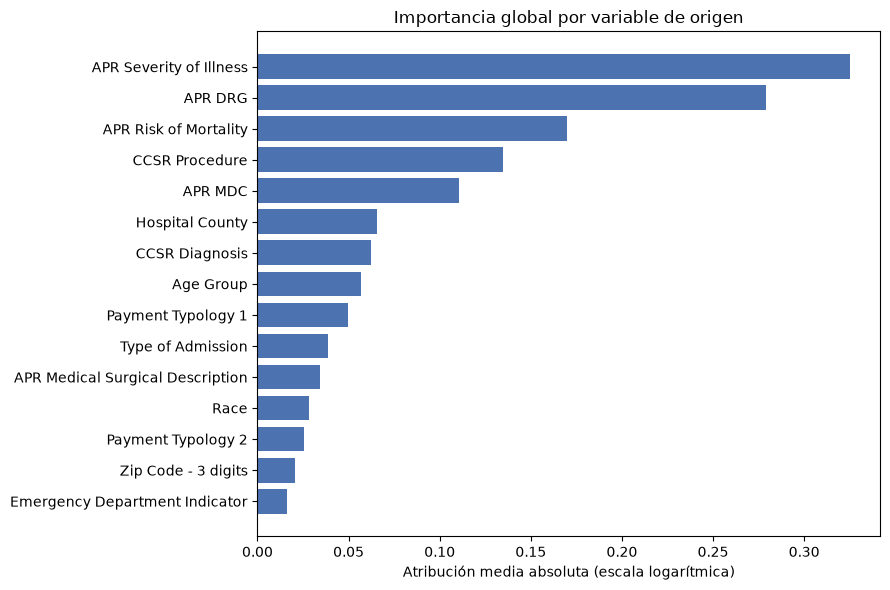

In [7]:
# Gráfico de importancia por variable de origen
top = importancia_var.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top["variable"], top["shap_medio_abs"], color="#4C72B0")
plt.xlabel("Atribución media absoluta (escala logarítmica)")
plt.title("Importancia global por variable de origen")
plt.tight_layout()
guardar_figura("importancia_por_variable")
plt.show()

## 7. Distribución de las atribuciones y dirección de los efectos

El gráfico de enjambre muestra, para cada columna, la distribución de sus atribuciones y su relación
con el valor de la variable. Permite leer no solo la magnitud del efecto sino su **dirección**: si
valores altos de la variable empujan la predicción hacia arriba o hacia abajo.

Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_beeswarm.png


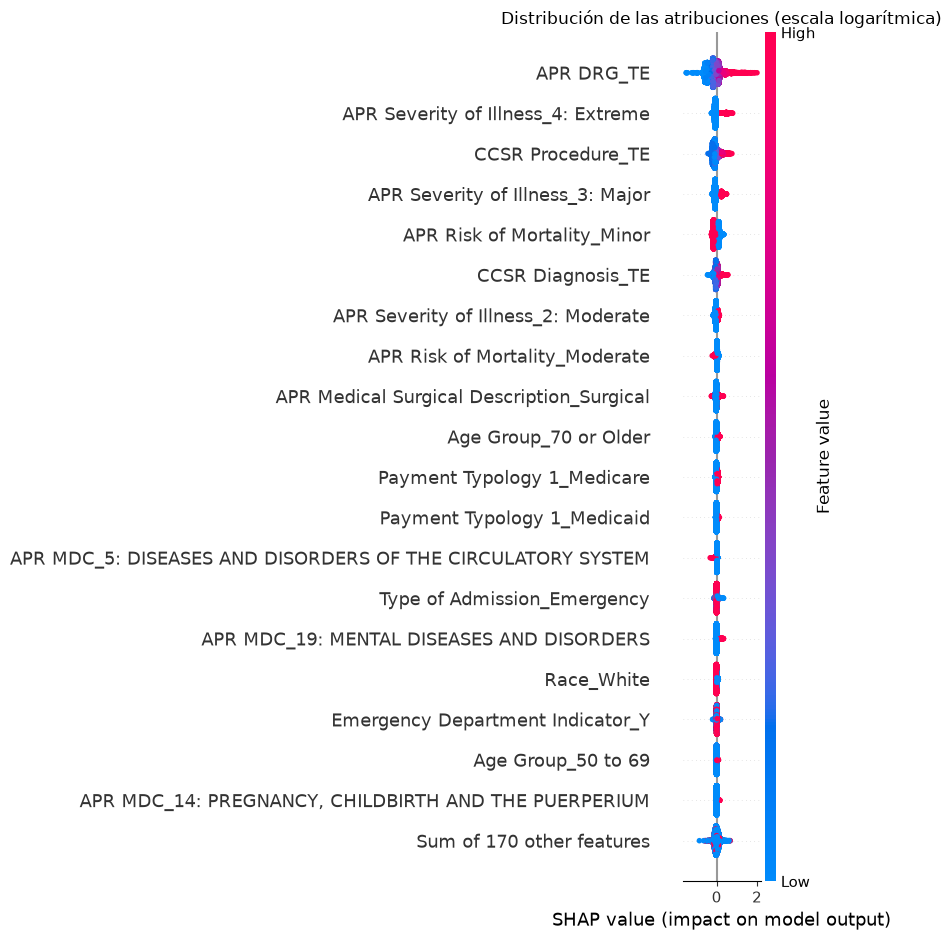

In [8]:
plt.figure()
shap.plots.beeswarm(sv, max_display=20, show=False)
plt.title("Distribución de las atribuciones (escala logarítmica)")
plt.tight_layout()
guardar_figura("beeswarm")
plt.show()

Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_barras_columnas.png


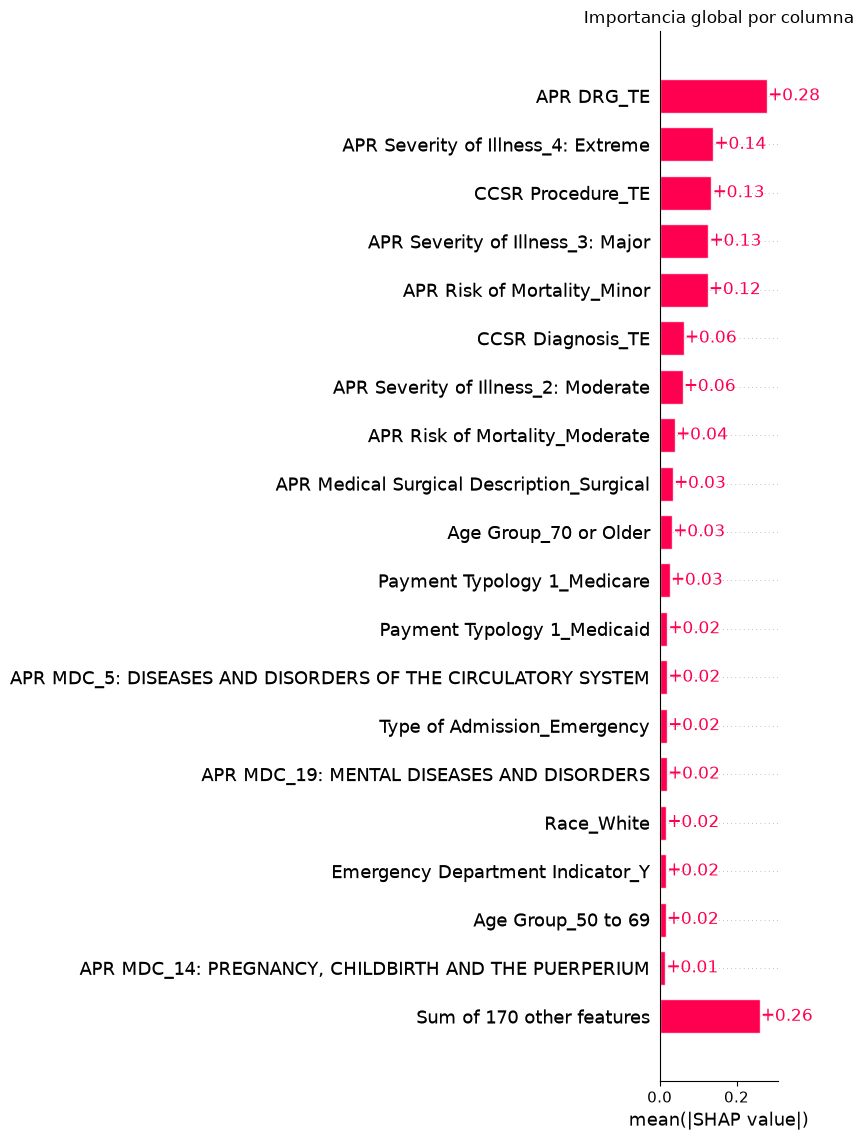

In [9]:
plt.figure()
shap.plots.bar(sv, max_display=20, show=False)
plt.title("Importancia global por columna")
plt.tight_layout()
guardar_figura("barras_columnas")
plt.show()

## 8. Gráficos de dependencia

Para las variables más influyentes se examina cómo varía la atribución en función del valor de la
variable. En las variables codificadas mediante \emph{Target Encoding} el eje horizontal corresponde
a la estancia media del grupo diagnóstico, de modo que el gráfico revela si el modelo reproduce esa
relación de forma lineal o si la modula.

Columnas seleccionadas: ['APR DRG_TE', 'APR Severity of Illness_4: Extreme', 'CCSR Procedure_TE', 'APR Severity of Illness_3: Major', 'APR Risk of Mortality_Minor', 'CCSR Diagnosis_TE']
Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_dependencia_APR_DRG_TE.png


<Figure size 640x480 with 0 Axes>

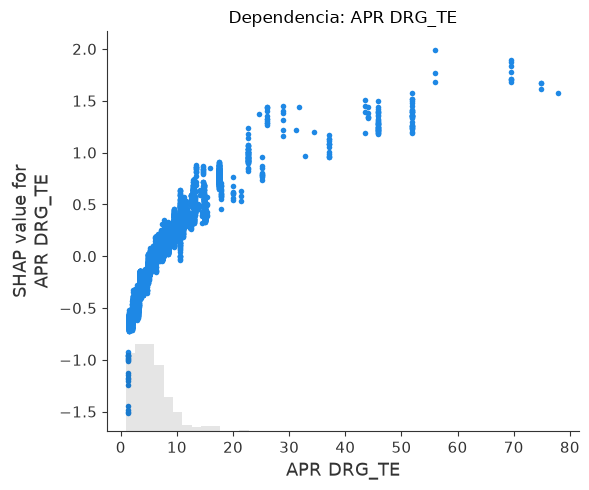

Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_dependencia_APR_Severity_of_Illness_4:_Extreme.png


<Figure size 640x480 with 0 Axes>

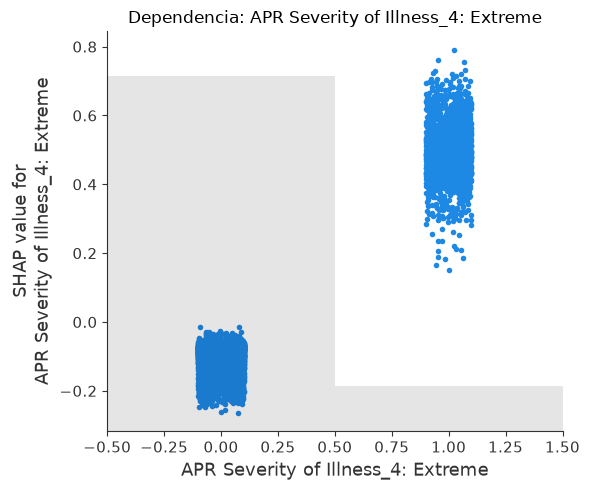

Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_dependencia_CCSR_Procedure_TE.png


<Figure size 640x480 with 0 Axes>

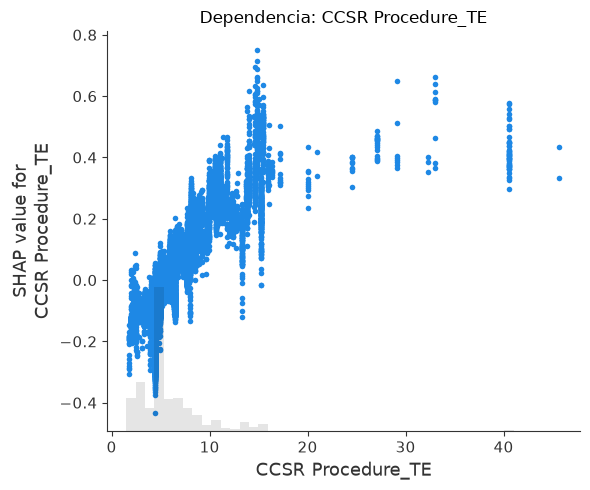

Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_dependencia_APR_Severity_of_Illness_3:_Major.png


<Figure size 640x480 with 0 Axes>

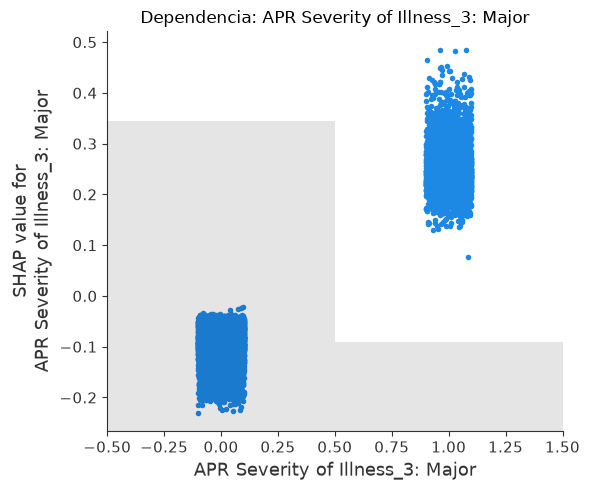

Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_dependencia_APR_Risk_of_Mortality_Minor.png


<Figure size 640x480 with 0 Axes>

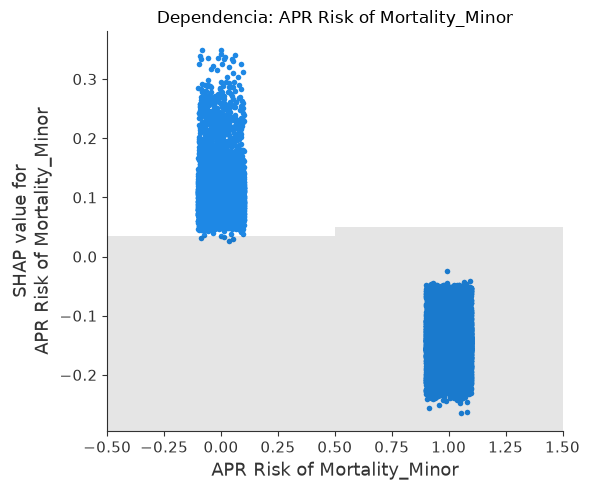

Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_dependencia_CCSR_Diagnosis_TE.png


<Figure size 640x480 with 0 Axes>

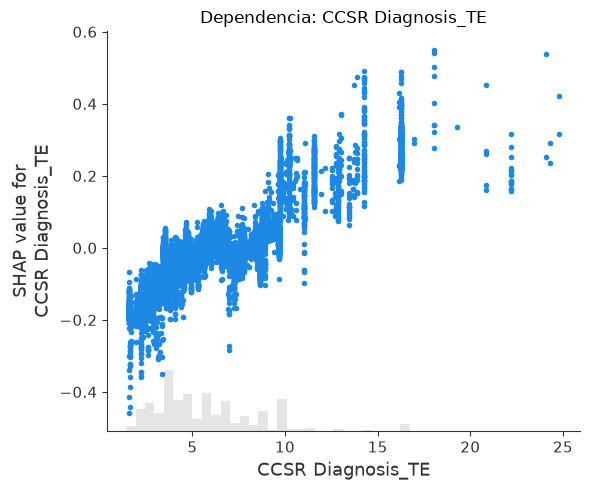

In [10]:
TOP_DEPENDENCIA = importancia["columna"].head(6).tolist()
print("Columnas seleccionadas:", TOP_DEPENDENCIA)

for col in TOP_DEPENDENCIA:
    plt.figure()
    shap.plots.scatter(sv[:, col], show=False)
    plt.title(f"Dependencia: {col}")
    plt.tight_layout()
    guardar_figura(f"dependencia_{col.replace(' ', '_').replace('/', '_')}")
    plt.show()

## 9. Contraste con la expectativa clínica

El control de calidad del \emph{Target Encoding} (cuaderno 03) estableció un ordenamiento clínico
esperado: el trasplante cardíaco, la prematuridad con bajo peso al nacer y las leucemias agudas en el
extremo de mayor duración; la obesidad, la amigdalitis y el dolor torácico inespecífico en el opuesto.
Esta sección verifica si el modelo reproduce ese ordenamiento, contrastando la atribución media con la
estancia real observada por tramo de la variable diagnóstica.

In [11]:
COL_DIAG = "APR DRG_TE" if "APR DRG_TE" in muestra.columns else importancia["columna"].iloc[0]
print(f"Variable diagnóstica empleada: {COL_DIAG}\n")

tramos_te = pd.qcut(muestra[COL_DIAG], q=10, duplicates="drop")
contraste = pd.DataFrame({
    "decil_estancia_esperada_del_grupo": tramos_te,
    "shap": sv_df[COL_DIAG].values,
    "estancia_real": y_muestra.values,
    "valor_te": muestra[COL_DIAG].values,
}).groupby("decil_estancia_esperada_del_grupo", observed=True).agg(
    n=("shap", "size"),
    te_medio=("valor_te", "mean"),
    shap_medio=("shap", "mean"),
    estancia_real_media=("estancia_real", "mean"),
)
contraste["factor"] = np.exp(contraste["shap_medio"])
contraste["efecto_pct"] = (contraste["factor"] - 1) * 100

display(contraste.round(3))
guardar_tabla(contraste, "ContrasteClinico")

corr = np.corrcoef(contraste["te_medio"], contraste["shap_medio"])[0, 1]
print(f"\nCorrelación entre la estancia esperada del grupo y la atribución media: {corr:.3f}")
print("Una correlación alta confirma que el modelo utiliza la información diagnóstica")
print("en la dirección clínicamente esperada.")

Variable diagnóstica empleada: APR DRG_TE



,n,te_medio,shap_medio,estancia_real_media,factor,efecto_pct
decil_estancia_esperada_del_grupo,,,,,,
"(1.348, 2.055]",2047,1.966,-0.598,1.921,0.550,-44.991001
"(2.055, 2.636]",1957,2.305,-0.472,2.332,0.624,-37.604000
"(2.636, 3.449]",2121,3.145,-0.348,3.274,0.706,-29.379000
"(3.449, 4.161]",1933,3.846,-0.286,3.951,0.751,-24.879000
"(4.161, 4.711]",2065,4.458,-0.197,4.582,0.821,-17.868000
"(4.711, 5.625]",1897,5.061,-0.100,5.103,0.905,-9.481000
"(5.625, 6.484]",1980,6.029,0.019,5.902,1.019,1.938000
"(6.484, 7.524]",2005,7.107,0.069,7.157,1.071,7.148000
"(7.524, 9.438]",2058,8.442,0.134,8.414,1.143,14.335000


Tabla guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\tablas\11_ContrasteClinico.csv

Correlación entre la estancia esperada del grupo y la atribución media: 0.963
Una correlación alta confirma que el modelo utiliza la información diagnóstica
en la dirección clínicamente esperada.


## 10. Auditoría de variables sensibles

El conjunto incluye variables cuyo uso por parte del modelo conviene examinar de forma explícita:
raza, etnia, tipo de pagador y área de residencia. Abakasanga et al. (2025) muestran que en la
predicción de la estancia el modelo de mejor desempeño no coincide necesariamente con el más
equitativo, por lo que esta verificación no es accesoria.

La cuestión no es si esas variables reciben atribución alguna —pueden hacerlo por razones clínicas o
de acceso legítimas— sino qué magnitud relativa alcanza frente a las variables clínicas.

In [12]:
SENSIBLES = ["Race", "Ethnicity", "Zip Code - 3 digits", "Payment Typology 1",
             "Payment Typology 2", "Payment Typology 3", "Gender"]

presentes = [v for v in SENSIBLES if v in importancia_var["variable"].values]
faltan = [v for v in SENSIBLES if v not in importancia_var["variable"].values]
if faltan:
    print("No encontradas (revisar nombres):", faltan)
    print("Variables disponibles:", list(importancia_var["variable"].values), "\n")

auditoria = importancia_var[importancia_var["variable"].isin(presentes)].copy()
auditoria["posicion_en_ranking"] = [
    int(importancia_var.index[importancia_var["variable"] == v][0]) + 1 for v in auditoria["variable"]
]
display(auditoria.round(4))
guardar_tabla(auditoria, "AuditoriaVariablesSensibles")

print(f"\nLas variables sensibles concentran {auditoria['pct_del_total'].sum():.1f}% de la")
print("atribución total del modelo.")

,variable,n_columnas,shap_medio_abs,factor_medio,efecto_pct,pct_del_total,posicion_en_ranking
8,Payment Typology 1,8,0.0498,1.0511,5.1085,3.4189,9
11,Race,3,0.0280,1.0284,2.8400,1.9216,12
12,Payment Typology 2,9,0.0257,1.0260,2.6034,1.7636,13
13,Zip Code - 3 digits,49,0.0207,1.0209,2.0868,1.4172,14
16,Gender,2,0.0113,1.0113,1.1326,0.7729,17
17,Payment Typology 3,9,0.0085,1.0085,0.8495,0.5805,18
18,Ethnicity,3,0.0073,1.0073,0.7332,0.5013,19


Tabla guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\tablas\11_AuditoriaVariablesSensibles.csv

Las variables sensibles concentran 10.4% de la
atribución total del modelo.


## 11. Explicaciones locales

Las atribuciones individuales muestran cómo el modelo construye la predicción de un episodio
concreto. Se seleccionan tres casos: uno de estancia breve, uno próximo a la mediana y uno de la cola
prolongada.

Estancia breve (1 día): estancia real = 1 días, predicción = 2.02 días
Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_waterfall_breve.png


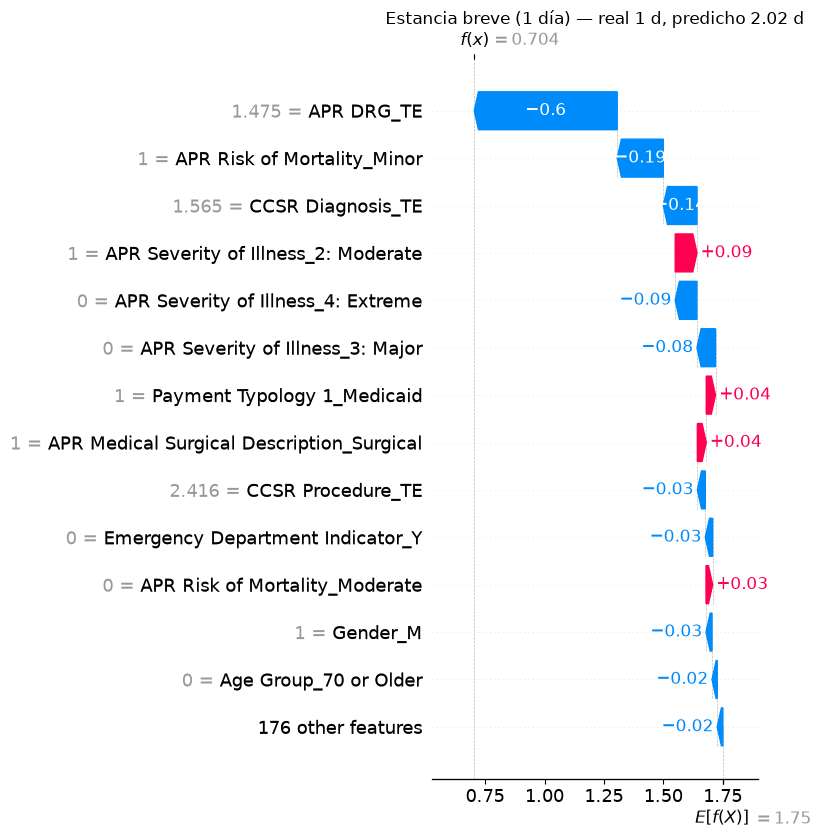

Estancia mediana (3 días): estancia real = 3 días, predicción = 5.62 días
Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_waterfall_mediana.png


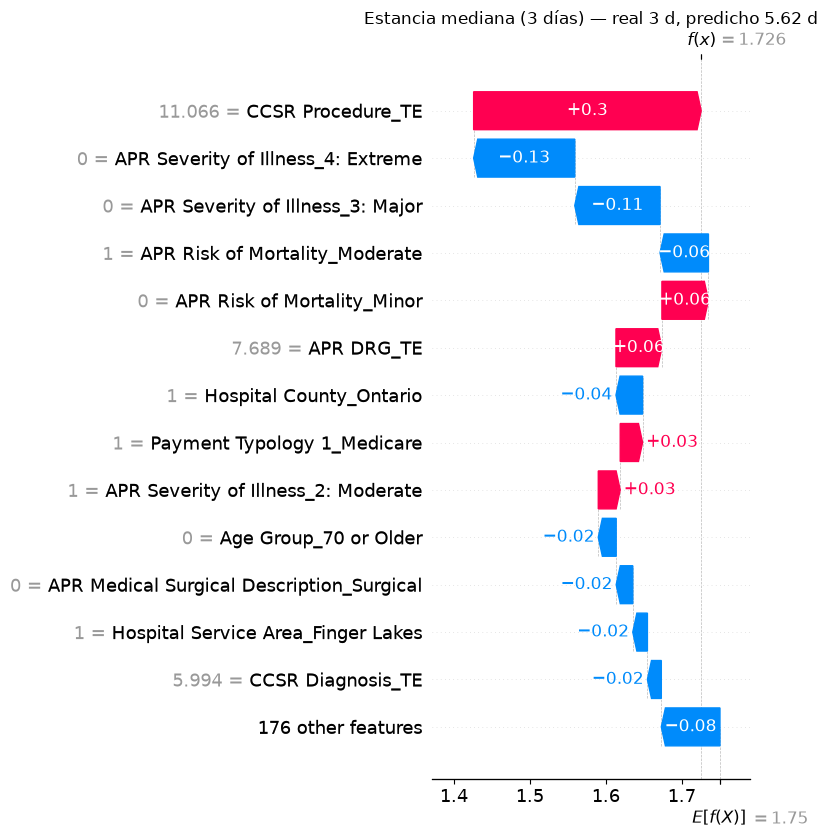

Estancia prolongada (>30 días): estancia real = 32 días, predicción = 7.06 días
Figura guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\figuras\11_waterfall_prolongada.png


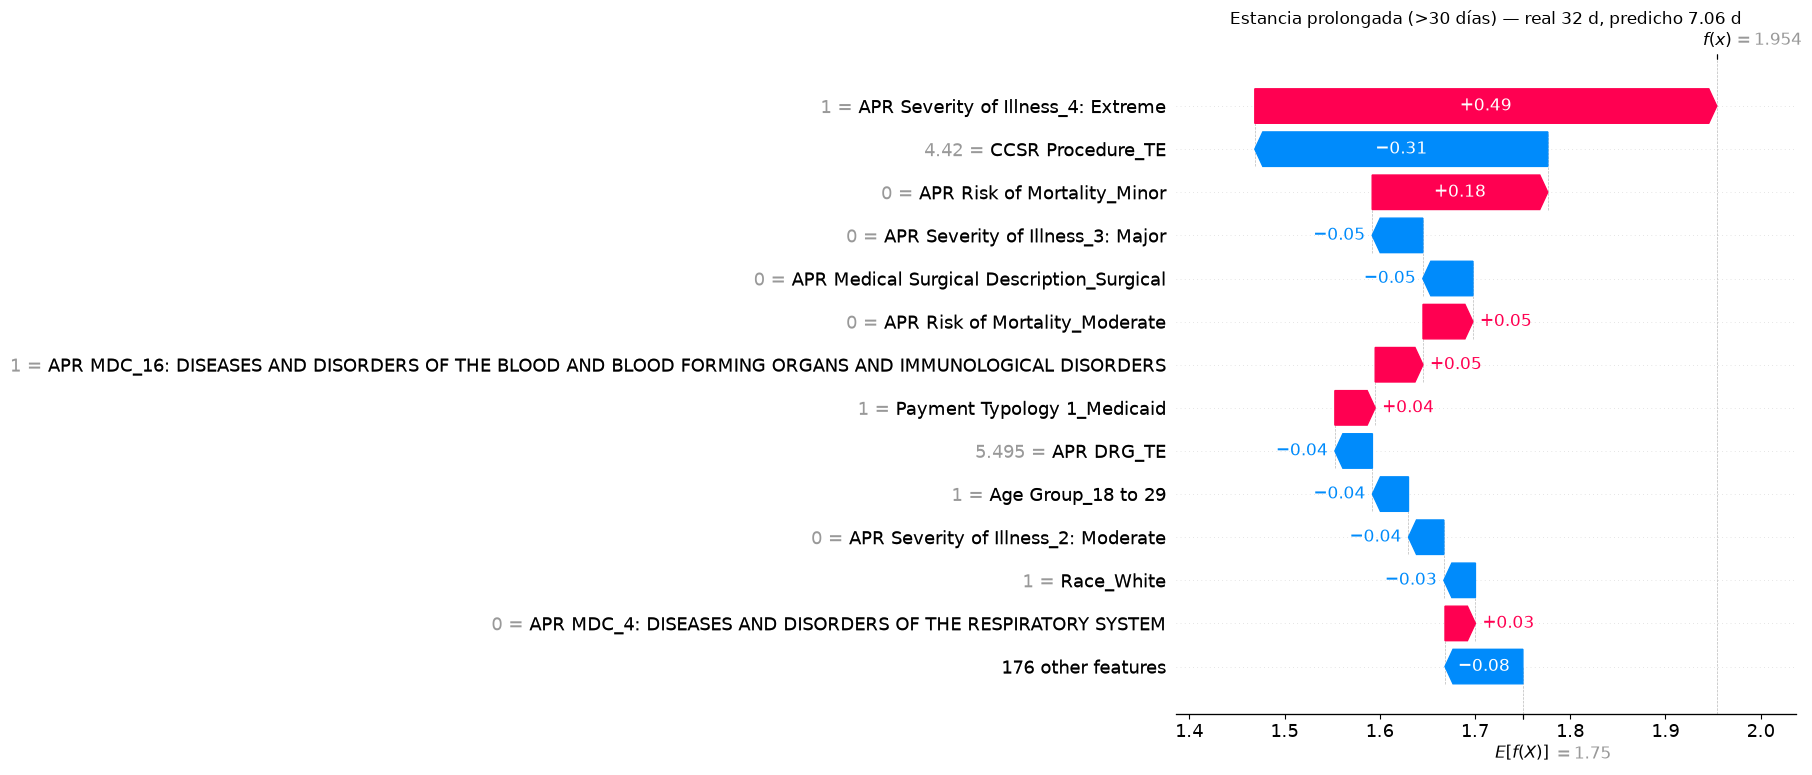

In [13]:
casos = {
    "Estancia breve (1 día)": y_muestra[y_muestra == 1].index[0],
    "Estancia mediana (3 días)": y_muestra[y_muestra == 3].index[0],
    "Estancia prolongada (>30 días)": y_muestra[y_muestra > 30].index[0],
}

pos = {k: muestra.index.get_loc(v) for k, v in casos.items()}

for etiqueta, i in pos.items():
    real = y_muestra.iloc[i]
    pred = modelo.predict(muestra.iloc[[i]])[0]
    print(f"{etiqueta}: estancia real = {real:.0f} días, predicción = {pred:.2f} días")

    plt.figure()
    shap.plots.waterfall(sv[i], max_display=14, show=False)
    plt.title(f"{etiqueta} — real {real:.0f} d, predicho {pred:.2f} d")
    plt.tight_layout()
    guardar_figura(f"waterfall_{etiqueta.split(' ')[1].lower()}")
    plt.show()

En los gráficos anteriores el eje inferior corresponde a la escala logarítmica. Para traducir una
atribución a su efecto sobre la estancia esperada basta exponenciarla: una barra de $+0{,}5$
multiplica la estimación por $1{,}65$.

## 12. Atribuciones por tramo de estancia

Esta sección examina si el modelo se apoya en las mismas variables a lo largo de toda la distribución
o si su razonamiento cambia entre las estancias breves y las prolongadas. Es la contrapartida
interpretativa del diagnóstico de la Sección 4.3 del documento, que situó la limitación del modelo en
la estimación de la magnitud de las estancias largas.

In [14]:
TRAMOS = [(1, 2, "1-2 días"), (3, 6, "3-6 días"), (7, 13, "7-13 días"),
          (14, 120, "14+ días")]

TOP_VARS = importancia_var["variable"].head(8).tolist()
abs_top = abs_por_variable[TOP_VARS]

filas = []
for lo, hi, etiqueta in TRAMOS:
    m = ((y_muestra >= lo) & (y_muestra <= hi)).to_numpy()
    if m.sum() == 0:
        continue
    fila = {"tramo": etiqueta, "n": int(m.sum())}
    fila.update(abs_top[m].mean().round(4).to_dict())
    filas.append(fila)

por_tramo_shap = pd.DataFrame(filas).set_index("tramo")
display(por_tramo_shap)
guardar_tabla(por_tramo_shap, "AtribucionPorTramo")

print("\nSi el ordenamiento de las variables cambia entre tramos, el modelo está empleando")
print("estructuras distintas para explicar las estancias breves y las prolongadas.")

,n,APR Severity of Illness,APR DRG,APR Risk of Mortality,CCSR Procedure,APR MDC,Hospital County,CCSR Diagnosis,Age Group
tramo,,,,,,,,,
1-2 días,7994,0.2816,0.3469,0.1816,0.1233,0.1104,0.0615,0.0706,0.0551
3-6 días,7127,0.3226,0.2182,0.1665,0.1263,0.1086,0.0649,0.0516,0.0600
7-13 días,3144,0.3842,0.1985,0.1594,0.1514,0.1109,0.0703,0.0564,0.0584
14+ días,1735,0.4314,0.3624,0.1488,0.1906,0.1191,0.0784,0.0793,0.0509


Tabla guardada: C:\Users\julia\OneDrive - Universidad Externado de Colombia\Shortcuts\Daniel Humberto Vallejo Vecil's files - Tesis\SPARCS\tablas\11_AtribucionPorTramo.csv

Si el ordenamiento de las variables cambia entre tramos, el modelo está empleando
estructuras distintas para explicar las estancias breves y las prolongadas.


## 13. Síntesis para el documento

Elementos a reportar en el capítulo de resultados:

1. **El valor base del modelo**, que corresponde a la estancia esperada en ausencia de información
   sobre el episodio, y frente al cual se interpretan todas las atribuciones.
2. **El ranking de importancia por variable de origen** (Sección 6), que es el que responde a la
   pregunta de investigación. El ranking por columna se reporta como material complementario, dado
   que fragmenta cada variable entre sus categorías.
3. **La dirección de los efectos** (Secciones 7 y 8), leída en términos multiplicativos.
4. **El contraste con la expectativa clínica** (Sección 9): si la correlación entre la estancia
   esperada del grupo diagnóstico y la atribución media es alta, el modelo utiliza la información
   clínica en la dirección esperada, lo que constituye una validación interna del resultado.
5. **La auditoría de variables sensibles** (Sección 10), con su posición en el ranking y su
   participación en la atribución total.
6. **Al menos una explicación local** (Sección 11), preferiblemente la del episodio prolongado, por
   ser el segmento de mayor interés operativo.
7. **La comparación de atribuciones entre tramos** (Sección 12), que conecta el análisis de
   interpretabilidad con el diagnóstico del error.

**Tablas exportadas:** `11_ImportanciaGlobalPorColumna`, `11_ImportanciaPorVariable`,
`11_ContrasteClinico`, `11_AuditoriaVariablesSensibles`, `11_AtribucionPorTramo`.

**Figuras exportadas:** `11_importancia_por_variable`, `11_beeswarm`, `11_barras_columnas`,
`11_dependencia_*`, `11_waterfall_*`.